## **Model 1: Baseline U-Net**

In [ ]:
!pip install -q segmentation-models-pytorch

# 1. Imports
from google.colab import drive
drive.mount('/content/drive')

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torch.amp import autocast, GradScaler

import segmentation_models_pytorch as smp

# 2. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

# 3. Dataset Paths
DATASET_PATH = "/content/drive/MyDrive/AAI/Task1/FoodSeg103"

TRAIN_IMAGE_PATH = os.path.join(DATASET_PATH, "Images", "img_dir", "train")
TRAIN_MASK_PATH  = os.path.join(DATASET_PATH, "Images", "ann_dir", "train")

TEST_IMAGE_PATH = os.path.join(DATASET_PATH, "Images", "img_dir", "test")
TEST_MASK_PATH  = os.path.join(DATASET_PATH, "Images", "ann_dir", "test")

assert os.path.exists(TRAIN_IMAGE_PATH), f"Missing: {TRAIN_IMAGE_PATH}"
assert os.path.exists(TRAIN_MASK_PATH),  f"Missing: {TRAIN_MASK_PATH}"
assert os.path.exists(TEST_IMAGE_PATH),  f"Missing: {TEST_IMAGE_PATH}"
assert os.path.exists(TEST_MASK_PATH),   f"Missing: {TEST_MASK_PATH}"

print("Train images:", len(os.listdir(TRAIN_IMAGE_PATH)))
print("Train masks :", len(os.listdir(TRAIN_MASK_PATH)))
print("Test images :", len(os.listdir(TEST_IMAGE_PATH)))
print("Test masks  :", len(os.listdir(TEST_MASK_PATH)))

# 4. File Lists
train_images = sorted([x for x in os.listdir(TRAIN_IMAGE_PATH) if x.lower().endswith(".jpg")])
test_images  = sorted([x for x in os.listdir(TEST_IMAGE_PATH) if x.lower().endswith(".jpg")])

train_image_paths = [os.path.join(TRAIN_IMAGE_PATH, x) for x in train_images]
train_mask_paths  = [os.path.join(TRAIN_MASK_PATH, x.replace(".jpg", ".png")) for x in train_images]

test_image_paths = [os.path.join(TEST_IMAGE_PATH, x) for x in test_images]
test_mask_paths  = [os.path.join(TEST_MASK_PATH, x.replace(".jpg", ".png")) for x in test_images]

for p in train_mask_paths[:10] + test_mask_paths[:10]:
    assert os.path.exists(p), f"Missing mask file: {p}"

print("\nTotal train samples:", len(train_image_paths))
print("Total test samples :", len(test_image_paths))

# 5. Example Visualisation
sample_idx = random.randint(0, len(train_image_paths) - 1)

image_path = train_image_paths[sample_idx]
mask_path = train_mask_paths[sample_idx]

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Food Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Segmentation Mask")
plt.axis("off")

plt.show()

print("Sample image file:", os.path.basename(image_path))
print("Image shape:", image.shape)
print("Mask shape :", mask.shape)
print("Unique mask values:", np.unique(mask)[:20], "...")
print("Number of unique labels in mask:", len(np.unique(mask)))

# 6. Dataset Classes
IMG_SIZE = 256
NUM_CLASSES = 104

class FoodSegDataset(Dataset):
    def __init__(self, image_paths, mask_paths, img_size=256):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.img_size = img_size

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]

        image = cv2.imread(image_path)
        if image is None:
            raise ValueError(f"Failed to read image: {image_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.img_size, self.img_size))
        image = image.astype(np.float32) / 255.0
        image = np.transpose(image, (2, 0, 1))  # HWC -> CHW
        image = torch.tensor(image, dtype=torch.float32)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise ValueError(f"Failed to read mask: {mask_path}")
        mask = cv2.resize(mask, (self.img_size, self.img_size), interpolation=cv2.INTER_NEAREST)
        mask = torch.tensor(mask, dtype=torch.long)

        return image, mask

# 7. Creating Datasets
full_train_dataset = FoodSegDataset(train_image_paths, train_mask_paths, img_size=IMG_SIZE)
test_dataset = FoodSegDataset(test_image_paths, test_mask_paths, img_size=IMG_SIZE)

print("Full train dataset size:", len(full_train_dataset))
print("Test dataset size      :", len(test_dataset))

# 8. Train/validation Split
VAL_RATIO = 0.1

indices = list(range(len(full_train_dataset)))
random.shuffle(indices)

split = int((1.0 - VAL_RATIO) * len(indices))
train_indices = indices[:split]
val_indices   = indices[split:]

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset   = Subset(full_train_dataset, val_indices)

print("Train split:", len(train_dataset))
print("Val split  :", len(val_dataset))
print("Test set   :", len(test_dataset))

# 9. DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

# 10. Build baseline U-Net
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(device)

print(model.__class__.__name__)
print("Model moved to:", device)

# 11. Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

# 12. Trial on One Batch
images, masks = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch mask shape :", masks.shape)
print("Image dtype:", images.dtype)
print("Mask dtype :", masks.dtype)
print("Mask min value:", masks.min().item())
print("Mask max value:", masks.max().item())

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)

print("Model output shape:", outputs.shape)

# 13. mIoU Evaluation
def evaluate_segmentation(model, dataloader, num_classes=104, device='cuda'):
    model.eval()
    confmat = torch.zeros((num_classes, num_classes), dtype=torch.int64, device=device)

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with autocast(device_type='cuda', enabled=torch.cuda.is_available()):
                outputs = model(images)

            preds = torch.argmax(outputs, dim=1)

            preds = preds.view(-1)
            masks = masks.view(-1)

            valid = (masks >= 0) & (masks < num_classes)
            preds = preds[valid]
            masks = masks[valid]

            indices = masks * num_classes + preds
            confmat += torch.bincount(
                indices,
                minlength=num_classes ** 2
            ).reshape(num_classes, num_classes)

    confmat = confmat.float()

    tp = torch.diag(confmat)
    gt = confmat.sum(dim=1)
    pred = confmat.sum(dim=0)

    pixel_accuracy = tp.sum() / torch.clamp(confmat.sum(), min=1)

    union = gt + pred - tp
    iou = tp / torch.clamp(union, min=1)
    dice = 2 * tp / torch.clamp(gt + pred, min=1)

    valid_classes = union > 0
    miou = iou[valid_classes].mean()
    mean_dice = dice[valid_classes].mean()

    per_class_iou = {cls: iou[cls].item() for cls in range(num_classes) if valid_classes[cls]}
    per_class_dice = {cls: dice[cls].item() for cls in range(num_classes) if valid_classes[cls]}

    return {
        "pixel_accuracy": pixel_accuracy.item(),
        "miou": miou.item(),
        "mean_dice": mean_dice.item(),
        "per_class_iou": per_class_iou,
        "per_class_dice": per_class_dice
    }

# 14. Training Loop
EPOCHS = 40
scaler = GradScaler('cuda', enabled=torch.cuda.is_available())

SAVE_DIR = "/content/drive/MyDrive/AAI/Task1/model_outputs_baseline"
os.makedirs(SAVE_DIR, exist_ok=True)

best_model_path = os.path.join(SAVE_DIR, "baseline_best_model.pth")

train_losses = []
val_mious = []
best_val_miou = 0.0

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        with autocast(device_type='cuda', enabled=torch.cuda.is_available()):
            outputs = model(images)
            loss = criterion(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)

    val_results = evaluate_segmentation(
        model=model,
        dataloader=val_loader,
        num_classes=NUM_CLASSES,
        device=device
    )
    val_miou = val_results["miou"]
    val_mious.append(val_miou)

    if val_miou > best_val_miou:
        best_val_miou = val_miou
        torch.save(model.state_dict(), best_model_path)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {avg_loss:.4f} | "
        f"Val mIoU: {val_miou:.4f} | "
        f"Best Val mIoU: {best_val_miou:.4f}"
    )

print("\nBest validation mIoU:", best_val_miou)
print("Best model saved to :", best_model_path)

# 15. Loading Best Model
model.load_state_dict(torch.load(best_model_path, map_location=device))
print("Loaded best baseline model.")

# 16. Test Evaluation
results = evaluate_segmentation(
    model=model,
    dataloader=test_loader,
    num_classes=NUM_CLASSES,
    device=device
)

print("\nFINAL TEST RESULTS")
print("Pixel Accuracy   :", results["pixel_accuracy"])
print("Mean IoU (mIoU)  :", results["miou"])
print("Mean Dice / F1   :", results["mean_dice"])

print("\nFirst 10 class IoU values:")
for cls, score in list(results["per_class_iou"].items())[:10]:
    print(f"Class {cls}: IoU = {score:.4f}")

print("\nFirst 10 class Dice values:")
for cls, score in list(results["per_class_dice"].items())[:10]:
    print(f"Class {cls}: Dice = {score:.4f}")

# 17. Plot Training Curves
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, marker='o')
plt.title("Baseline Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(val_mious, marker='o')
plt.title("Baseline Validation mIoU")
plt.xlabel("Epoch")
plt.ylabel("mIoU")

plt.tight_layout()
plt.show()

# 18. Image Visualisation
idx = random.randint(0, len(test_dataset) - 1)
image, mask = test_dataset[idx]

image_input = image.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(image_input)
    pred = torch.argmax(output, dim=1)

image_np = image.numpy()
mask_np = mask.numpy()
pred_np = pred.squeeze().cpu().numpy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_np.transpose(1, 2, 0))
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_np)
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_np)
plt.title("Predicted Mask")
plt.axis("off")

plt.show()

# 19. Coloured Mask Visualisation
def create_color_map(num_classes=104):
    np.random.seed(42)
    colors = np.random.randint(0, 255, size=(num_classes, 3))
    colors[0] = [0, 0, 0]
    return colors

def mask_to_color(mask, color_map):
    h, w = mask.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)

    for cls in range(len(color_map)):
        color_mask[mask == cls] = color_map[cls]

    return color_mask

color_map = create_color_map(NUM_CLASSES)

idx = random.randint(0, len(test_dataset) - 1)
image, mask = test_dataset[idx]

inp = image.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(inp)
    pred = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()

mask_np = mask.cpu().numpy()
gt_color = mask_to_color(mask_np, color_map)
pred_color = mask_to_color(pred, color_map)

image_np = image.permute(1, 2, 0).cpu().numpy()
image_np = np.clip(image_np, 0, 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gt_color)
plt.title("Ground Truth (Colored)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_color)
plt.title("Prediction (Colored)")
plt.axis("off")

plt.show()

# 20. Saving Summary
summary_path = os.path.join(SAVE_DIR, "baseline_results_summary.txt")

with open(summary_path, "w") as f:
    f.write("MODEL 1 BASELINE RESULTS\n")
    f.write("========================\n\n")
    f.write(f"Best validation mIoU: {best_val_miou:.6f}\n")
    f.write(f"Final test pixel accuracy: {results['pixel_accuracy']:.6f}\n")
    f.write(f"Final test mIoU: {results['miou']:.6f}\n")
    f.write(f"Final test mean Dice: {results['mean_dice']:.6f}\n\n")
    f.write("Model: U-Net with ResNet34 encoder\n")
    f.write("Image size: 256x256\n")
    f.write("Batch size: 16\n")
    f.write("Epochs: 8\n")
    f.write("Loss: CrossEntropyLoss\n")
    f.write("Optimizer: Adam\n")
    f.write("Learning rate: 1e-4\n")
    f.write("Train/Val split: 90/10\n")
    f.write("No augmentation\n")

print("\nSummary saved to:", summary_path)

# Metrics Evaluation

def evaluate_additional_metrics(model, dataloader, num_classes=104, device='cuda'):
    model.eval()
    confmat = torch.zeros((num_classes, num_classes), dtype=torch.int64, device=device)

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with autocast(device_type='cuda', enabled=torch.cuda.is_available()):
                outputs = model(images)

            preds = torch.argmax(outputs, dim=1)

            preds = preds.view(-1)
            masks = masks.view(-1)

            valid = (masks >= 0) & (masks < num_classes)
            preds = preds[valid]
            masks = masks[valid]

            indices = masks * num_classes + preds
            confmat += torch.bincount(
                indices,
                minlength=num_classes ** 2
            ).reshape(num_classes, num_classes)

    confmat = confmat.float()

    # Confusion-matrix
    tp = torch.diag(confmat)
    gt = confmat.sum(dim=1)
    pred = confmat.sum(dim=0)
    total = confmat.sum()

    fp = pred - tp
    fn = gt - tp
    tn = total - (tp + fp + fn)

    eps = 1e-7

    # Overall metrics
    pixel_accuracy = tp.sum() / (total + eps)

    # Per-class metrics
    iou = tp / (tp + fp + fn + eps)
    dice = 2 * tp / (2 * tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    specificity = tn / (tn + fp + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    class_accuracy = tp / (gt + eps)

    # Average Classes
    valid_classes = (gt + pred) > 0

    miou = iou[valid_classes].mean()
    mean_dice = dice[valid_classes].mean()
    mean_precision = precision[valid_classes].mean()
    mean_recall = recall[valid_classes].mean()
    mean_specificity = specificity[valid_classes].mean()
    mean_f1 = f1[valid_classes].mean()
    mean_class_accuracy = class_accuracy[valid_classes].mean()

    # Frequency Weighted IoU
    freq = gt / (total + eps)
    fwiou = (freq[valid_classes] * iou[valid_classes]).sum()

    # Per-class dictionaries
    per_class_iou = {cls: iou[cls].item() for cls in range(num_classes) if valid_classes[cls]}
    per_class_dice = {cls: dice[cls].item() for cls in range(num_classes) if valid_classes[cls]}
    per_class_precision = {cls: precision[cls].item() for cls in range(num_classes) if valid_classes[cls]}
    per_class_recall = {cls: recall[cls].item() for cls in range(num_classes) if valid_classes[cls]}
    per_class_specificity = {cls: specificity[cls].item() for cls in range(num_classes) if valid_classes[cls]}
    per_class_f1 = {cls: f1[cls].item() for cls in range(num_classes) if valid_classes[cls]}
    per_class_accuracy = {cls: class_accuracy[cls].item() for cls in range(num_classes) if valid_classes[cls]}

    return {
        "pixel_accuracy": pixel_accuracy.item(),
        "mean_class_accuracy": mean_class_accuracy.item(),
        "miou": miou.item(),
        "fwiou": fwiou.item(),
        "mean_dice": mean_dice.item(),
        "mean_precision": mean_precision.item(),
        "mean_recall": mean_recall.item(),
        "mean_specificity": mean_specificity.item(),
        "mean_f1": mean_f1.item(),
        "per_class_iou": per_class_iou,
        "per_class_dice": per_class_dice,
        "per_class_precision": per_class_precision,
        "per_class_recall": per_class_recall,
        "per_class_specificity": per_class_specificity,
        "per_class_f1": per_class_f1,
        "per_class_accuracy": per_class_accuracy
    }


# Run on test set
extra_results = evaluate_additional_metrics(
    model=model,
    dataloader=test_loader,
    num_classes=NUM_CLASSES,
    device=device
)

print("\nADDITIONAL TEST METRICS")
print(f"Pixel Accuracy         : {extra_results['pixel_accuracy']:.6f}")
print(f"Mean Class Accuracy    : {extra_results['mean_class_accuracy']:.6f}")
print(f"Mean IoU (mIoU)        : {extra_results['miou']:.6f}")
print(f"Frequency Weighted IoU : {extra_results['fwiou']:.6f}")
print(f"Mean Dice              : {extra_results['mean_dice']:.6f}")
print(f"Mean Precision         : {extra_results['mean_precision']:.6f}")
print(f"Mean Recall            : {extra_results['mean_recall']:.6f}")
print(f"Mean Specificity       : {extra_results['mean_specificity']:.6f}")
print(f"Mean F1-score          : {extra_results['mean_f1']:.6f}")

print("\nFirst 10 class IoU values:")
for cls, score in list(extra_results["per_class_iou"].items())[:10]:
    print(f"Class {cls}: IoU = {score:.4f}")

print("\nFirst 10 class Dice values:")
for cls, score in list(extra_results["per_class_dice"].items())[:10]:
    print(f"Class {cls}: Dice = {score:.4f}")

print("\nFirst 10 class Precision values:")
for cls, score in list(extra_results["per_class_precision"].items())[:10]:
    print(f"Class {cls}: Precision = {score:.4f}")

print("\nFirst 10 class Recall values:")
for cls, score in list(extra_results["per_class_recall"].items())[:10]:
    print(f"Class {cls}: Recall = {score:.4f}")

print("\nFirst 10 class Specificity values:")
for cls, score in list(extra_results["per_class_specificity"].items())[:10]:
    print(f"Class {cls}: Specificity = {score:.4f}")

print("\nFirst 10 class F1 values:")
for cls, score in list(extra_results["per_class_f1"].items())[:10]:
    print(f"Class {cls}: F1 = {score:.4f}")

print("\nFirst 10 class Accuracy values:")
for cls, score in list(extra_results["per_class_accuracy"].items())[:10]:
    print(f"Class {cls}: Accuracy = {score:.4f}")


# Saving additional metrics to a separate text file
extra_summary_path = os.path.join(SAVE_DIR, "baseline_additional_metrics.txt")

with open(extra_summary_path, "w") as f:
    f.write("MODEL 1 BASELINE - ADDITIONAL TEST METRICS\n")
    f.write("==========================================\n\n")
    f.write(f"Pixel Accuracy: {extra_results['pixel_accuracy']:.6f}\n")
    f.write(f"Mean Class Accuracy: {extra_results['mean_class_accuracy']:.6f}\n")
    f.write(f"Mean IoU (mIoU): {extra_results['miou']:.6f}\n")
    f.write(f"Frequency Weighted IoU: {extra_results['fwiou']:.6f}\n")
    f.write(f"Mean Dice: {extra_results['mean_dice']:.6f}\n")
    f.write(f"Mean Precision: {extra_results['mean_precision']:.6f}\n")
    f.write(f"Mean Recall: {extra_results['mean_recall']:.6f}\n")
    f.write(f"Mean Specificity: {extra_results['mean_specificity']:.6f}\n")
    f.write(f"Mean F1-score: {extra_results['mean_f1']:.6f}\n\n")

    f.write("First 10 class IoU values:\n")
    for cls, score in list(extra_results["per_class_iou"].items())[:10]:
        f.write(f"Class {cls}: IoU = {score:.6f}\n")

    f.write("\nFirst 10 class Dice values:\n")
    for cls, score in list(extra_results["per_class_dice"].items())[:10]:
        f.write(f"Class {cls}: Dice = {score:.6f}\n")

    f.write("\nFirst 10 class Precision values:\n")
    for cls, score in list(extra_results["per_class_precision"].items())[:10]:
        f.write(f"Class {cls}: Precision = {score:.6f}\n")

    f.write("\nFirst 10 class Recall values:\n")
    for cls, score in list(extra_results["per_class_recall"].items())[:10]:
        f.write(f"Class {cls}: Recall = {score:.6f}\n")

    f.write("\nFirst 10 class Specificity values:\n")
    for cls, score in list(extra_results["per_class_specificity"].items())[:10]:
        f.write(f"Class {cls}: Specificity = {score:.6f}\n")

    f.write("\nFirst 10 class F1 values:\n")
    for cls, score in list(extra_results["per_class_f1"].items())[:10]:
        f.write(f"Class {cls}: F1 = {score:.6f}\n")

    f.write("\nFirst 10 class Accuracy values:\n")
    for cls, score in list(extra_results["per_class_accuracy"].items())[:10]:
        f.write(f"Class {cls}: Accuracy = {score:.6f}\n")

print("\nAdditional metrics summary saved to:", extra_summary_path)

## **Model 2: Improved CNN (DeepLabV3+)**

In [ ]:
!pip install -q segmentation-models-pytorch albumentations opencv-python matplotlib timm

from google.colab import drive
drive.mount('/content/drive')

import os
import cv2
import time
import shutil
import random
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
import albumentations as A

from torch.utils.data import Dataset, DataLoader
from albumentations.pytorch import ToTensorV2
from collections import defaultdict

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True
except:
    pass

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Dataset path
DRIVE_DATASET_PATH = "/content/drive/MyDrive/AAI/Task1/FoodSeg103"
LOCAL_DATASET_PATH = "/content/FoodSeg103"

if not os.path.exists(LOCAL_DATASET_PATH):
    print("Copying dataset from Google Drive to local Colab storage...")
    shutil.copytree(DRIVE_DATASET_PATH, LOCAL_DATASET_PATH)
    print("Copy complete.")
else:
    print("Using existing local dataset copy.")

DATASET_PATH = LOCAL_DATASET_PATH

TRAIN_IMAGE_PATH = os.path.join(DATASET_PATH, "Images", "img_dir", "train")
TRAIN_MASK_PATH  = os.path.join(DATASET_PATH, "Images", "ann_dir", "train")
TEST_IMAGE_PATH  = os.path.join(DATASET_PATH, "Images", "img_dir", "test")
TEST_MASK_PATH   = os.path.join(DATASET_PATH, "Images", "ann_dir", "test")

assert os.path.exists(TRAIN_IMAGE_PATH), f"Missing: {TRAIN_IMAGE_PATH}"
assert os.path.exists(TRAIN_MASK_PATH),  f"Missing: {TRAIN_MASK_PATH}"
assert os.path.exists(TEST_IMAGE_PATH),  f"Missing: {TEST_IMAGE_PATH}"
assert os.path.exists(TEST_MASK_PATH),   f"Missing: {TEST_MASK_PATH}"

# File lists
train_images = sorted([x for x in os.listdir(TRAIN_IMAGE_PATH) if x.lower().endswith(".jpg")])
test_images  = sorted([x for x in os.listdir(TEST_IMAGE_PATH) if x.lower().endswith(".jpg")])

train_image_paths = [os.path.join(TRAIN_IMAGE_PATH, x) for x in train_images]
train_mask_paths  = [os.path.join(TRAIN_MASK_PATH, x.replace(".jpg", ".png")) for x in train_images]

test_image_paths  = [os.path.join(TEST_IMAGE_PATH, x) for x in test_images]
test_mask_paths   = [os.path.join(TEST_MASK_PATH, x.replace(".jpg", ".png")) for x in test_images]

print("Train images:", len(train_image_paths))
print("Test images :", len(test_image_paths))

# Hyperparameters
NUM_CLASSES = 104
IMG_SIZE = 448

BATCH_SIZE = 4
EPOCHS = 40
LR_MAX = 1e-4
WEIGHT_DECAY = 1e-4
VAL_RATIO = 0.1
NUM_WORKERS = 2
ACCUM_STEPS = 1
PATIENCE = 10

SAVE_DIR = "/content/drive/MyDrive/AAI/Task1/model_outputs_clean_baseline"
os.makedirs(SAVE_DIR, exist_ok=True)

best_model_path  = os.path.join(SAVE_DIR, "best_foodseg_model.pth")
summary_path     = os.path.join(SAVE_DIR, "foodseg_results_summary.txt")
curves_path      = os.path.join(SAVE_DIR, "foodseg_training_curves.png")
examples_path    = os.path.join(SAVE_DIR, "foodseg_predictions.png")
final_model_path = os.path.join(SAVE_DIR, "foodseg_final_model_state_dict.pth")

# Transforms
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_LINEAR),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.08,
        p=0.4
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_LINEAR),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

# Dataset
class FoodDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]

        img = cv2.imread(img_path)
        if img is None:
            raise ValueError(f"Failed to read image: {img_path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise ValueError(f"Failed to read mask: {mask_path}")

        if self.transform is not None:
            aug = self.transform(image=img, mask=mask)
            img = aug["image"]
            mask = aug["mask"].long()
        else:
            img = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
            mask = torch.from_numpy(mask).long()

        return img, mask

# Train / val split
indices = list(range(len(train_image_paths)))
random.shuffle(indices)

split = int((1.0 - VAL_RATIO) * len(indices))
train_idx = indices[:split]
val_idx   = indices[split:]

train_dataset = FoodDataset(
    [train_image_paths[i] for i in train_idx],
    [train_mask_paths[i] for i in train_idx],
    transform=train_transform
)

val_dataset = FoodDataset(
    [train_image_paths[i] for i in val_idx],
    [train_mask_paths[i] for i in val_idx],
    transform=val_transform
)

test_dataset = FoodDataset(
    test_image_paths,
    test_mask_paths,
    transform=val_transform
)

print("Train split:", len(train_dataset))
print("Val split  :", len(val_dataset))
print("Test set   :", len(test_dataset))

# Dataloaders
loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0)
)
if NUM_WORKERS > 0:
    loader_kwargs["prefetch_factor"] = 2

train_loader = DataLoader(train_dataset, shuffle=True, drop_last=True, **loader_kwargs)
val_loader   = DataLoader(val_dataset, shuffle=False, drop_last=False, **loader_kwargs)
test_loader  = DataLoader(test_dataset, shuffle=False, drop_last=False, **loader_kwargs)

# Sanity checks
images, masks = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch mask shape :", masks.shape)
print("Mask min/max     :", masks.min().item(), masks.max().item())

assert masks.min().item() >= 0, "Mask has negative label values."
assert masks.max().item() < NUM_CLASSES, f"Mask label exceeds NUM_CLASSES-1 ({NUM_CLASSES-1})."

#Visualization
def denorm_image(img_tensor):
    img = img_tensor.detach().cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img * std + mean
    img = np.clip(img, 0, 1)
    return img

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(denorm_image(images[0]))
plt.title("Sample image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(masks[0].cpu().numpy(), cmap="tab20")
plt.title("Sample mask")
plt.axis("off")
plt.show()

# Model
model = smp.DeepLabV3Plus(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES
).to(device)

print("Model ready.")

# Loss
ce_loss = nn.CrossEntropyLoss()

def loss_fn(logits, targets):
    return ce_loss(logits, targets)

# Optimizer + scheduler + AMP
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR_MAX,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=LR_MAX,
    epochs=EPOCHS,
    steps_per_epoch=len(train_loader),
    pct_start=0.15,
    anneal_strategy="cos"
)

use_amp = torch.cuda.is_available()
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except:
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

# Metrics
def update_confusion_matrix(confmat, preds, targets, num_classes):
    preds = preds.view(-1)
    targets = targets.view(-1)

    valid = (targets >= 0) & (targets < num_classes)
    preds = preds[valid]
    targets = targets[valid]

    inds = num_classes * targets + preds
    confmat += torch.bincount(
        inds,
        minlength=num_classes * num_classes
    ).reshape(num_classes, num_classes)

    return confmat

def compute_per_class_iou(confmat):
    confmat = confmat.float()
    intersection = torch.diag(confmat)
    union = confmat.sum(dim=1) + confmat.sum(dim=0) - intersection
    valid = union > 0
    iou = torch.zeros_like(intersection)
    iou[valid] = intersection[valid] / (union[valid] + 1e-7)
    return iou, valid

def compute_miou_from_confmat(confmat):
    iou, valid = compute_per_class_iou(confmat)
    if valid.sum() == 0:
        return 0.0
    return iou[valid].mean().item()

@torch.no_grad()
def predict_with_tta(model, images):
    logits = model(images)

    flipped_images = torch.flip(images, dims=[3])
    flipped_logits = model(flipped_images)
    flipped_logits = torch.flip(flipped_logits, dims=[3])

    return 0.5 * (logits + flipped_logits)

# Training loop
best_val_miou = 0.0
best_epoch = -1
epochs_without_improve = 0

train_losses = []
val_mious = []
lrs = []

for epoch in range(EPOCHS):
    start_time = time.time()

    # train
    model.train()
    running_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    for step, (images, masks) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            outputs = model(images)
            loss = loss_fn(outputs, masks) / ACCUM_STEPS

        scaler.scale(loss).backward()

        if (step + 1) % ACCUM_STEPS == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        running_loss += loss.item() * ACCUM_STEPS
        lrs.append(optimizer.param_groups[0]["lr"])

    avg_train_loss = running_loss / max(len(train_loader), 1)
    train_losses.append(avg_train_loss)

    # validation
    model.eval()
    confmat = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=device)

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            confmat = update_confusion_matrix(confmat, preds, masks, NUM_CLASSES)

    val_miou = compute_miou_from_confmat(confmat)
    val_mious.append(val_miou)

    if val_miou > best_val_miou:
        best_val_miou = val_miou
        best_epoch = epoch + 1
        epochs_without_improve = 0

        save_obj = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_miou": best_val_miou,
            "num_classes": NUM_CLASSES
        }
        torch.save(save_obj, best_model_path)
    else:
        epochs_without_improve += 1

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val mIoU: {val_miou:.4f} | "
        f"Best: {best_val_miou:.4f} | "
        f"Time: {time.time() - start_time:.1f}s"
    )

    if epochs_without_improve >= PATIENCE:
        print(f"\nEarly stopping triggered after {epoch+1} epochs.")
        break

print("\nBest validation mIoU:", best_val_miou)
print("Best epoch          :", best_epoch)

# Load best model
checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
print("Loaded best model.")

# Final test evaluation
model.eval()
test_confmat = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=device)

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        outputs = predict_with_tta(model, images)
        preds = torch.argmax(outputs, dim=1)

        test_confmat = update_confusion_matrix(test_confmat, preds, masks, NUM_CLASSES)

final_test_miou = compute_miou_from_confmat(test_confmat)
print("\nFINAL TEST mIoU:", final_test_miou)

# Save final plain state_dict as well
torch.save(model.state_dict(), final_model_path)
print("Saved final model state_dict.")

# Training curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses)
plt.title("Train Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(val_mious)
plt.title("Validation mIoU")
plt.xlabel("Epoch")
plt.ylabel("mIoU")

plt.tight_layout()
plt.savefig(curves_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved curves to: {curves_path}")

# Prediction examples
def colorize_mask(mask):
    """
    Simple deterministic coloring for visualization only.
    """
    rng = np.random.default_rng(123)
    colors = rng.integers(0, 255, size=(NUM_CLASSES, 3), dtype=np.uint8)
    return colors[mask]

model.eval()
sample_count = min(3, len(test_dataset))

fig, axes = plt.subplots(sample_count, 3, figsize=(12, 4 * sample_count))
if sample_count == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for i in range(sample_count):
        img, gt_mask = test_dataset[i]
        inp = img.unsqueeze(0).to(device)

        logits = predict_with_tta(model, inp)
        pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

        img_np = denorm_image(img)
        gt_np = gt_mask.cpu().numpy()

        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(colorize_mask(gt_np))
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(colorize_mask(pred_mask))
        axes[i, 2].set_title("Prediction")
        axes[i, 2].axis("off")

plt.tight_layout()
plt.savefig(examples_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved prediction examples to: {examples_path}")

# Save summary
with open(summary_path, "w") as f:
    f.write("FOODSEG103 CLEAN BASELINE RESULTS\n")
    f.write("=================================\n")
    f.write(f"Model: DeepLabV3+\n")
    f.write(f"Backbone: ResNet50 (ImageNet pretrained)\n")
    f.write(f"Input size: {IMG_SIZE}x{IMG_SIZE}\n")
    f.write(f"Batch size: {BATCH_SIZE}\n")
    f.write(f"Epochs requested: {EPOCHS}\n")
    f.write(f"Best epoch: {best_epoch}\n")
    f.write(f"Learning rate max: {LR_MAX}\n")
    f.write(f"Weight decay: {WEIGHT_DECAY}\n")
    f.write(f"Validation ratio: {VAL_RATIO}\n")
    f.write(f"Best validation mIoU: {best_val_miou:.6f}\n")
    f.write(f"Final test mIoU: {final_test_miou:.6f}\n")

print(f"Saved summary to: {summary_path}")

#PLots

try:
    class_names
    assert len(class_names) == NUM_CLASSES
except:
    class_names = [f"class_{i}" for i in range(NUM_CLASSES)]

# Helper functions
def build_fixed_colormap(num_classes, seed=123):
    rng = np.random.default_rng(seed)
    colors = rng.integers(0, 255, size=(num_classes, 3), dtype=np.uint8)
    colors[0] = np.array([128, 128, 128], dtype=np.uint8)  # class 0 in gray
    return colors

COLORS = build_fixed_colormap(NUM_CLASSES)

def colorize_mask(mask, colors=COLORS):
    return colors[mask]

def overlay_mask_on_image(image_rgb, mask, alpha=0.45, colors=COLORS):
    """
    image_rgb: float image in [0,1] or uint8 image in [0,255]
    mask: HxW integer mask
    """
    if image_rgb.dtype != np.uint8:
        base = (np.clip(image_rgb, 0, 1) * 255).astype(np.uint8)
    else:
        base = image_rgb.copy()

    color_mask = colorize_mask(mask, colors)
    overlay = cv2.addWeighted(base, 1 - alpha, color_mask, alpha, 0)
    return overlay

def get_connected_components_for_labels(mask, min_area=400):
    """
    Returns one representative bounding box per class label, using the largest connected component.
    """
    results = []
    labels_present = np.unique(mask)

    for cls_id in labels_present:
        binary = (mask == cls_id).astype(np.uint8)
        if binary.sum() == 0:
            continue

        num_cc, cc_map, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)

        best_area = 0
        best_box = None

        # skip component 0
        for comp_id in range(1, num_cc):
            x, y, w, h, area = stats[comp_id]
            if area >= min_area and area > best_area:
                best_area = area
                best_box = (x, y, w, h, area)

        if best_box is not None:
            results.append((cls_id, best_box))

    return results

def draw_labels(ax, mask, colors=COLORS, class_names=None, min_area=400, max_labels=8):
    """
    Draw one label box per class using its largest connected component.
    """
    comps = get_connected_components_for_labels(mask, min_area=min_area)

    # Sort by component area descending
    comps = sorted(comps, key=lambda x: x[1][4], reverse=True)[:max_labels]

    for cls_id, (x, y, w, h, area) in comps:
        color = colors[cls_id] / 255.0
        rect = patches.Rectangle(
            (x, y), w, h,
            linewidth=1.5,
            edgecolor=color,
            facecolor='none'
        )
        ax.add_patch(rect)

        label = class_names[cls_id] if class_names is not None else str(cls_id)
        ax.text(
            x,
            max(y - 4, 2),
            label,
            fontsize=9,
            color="white",
            bbox=dict(
                facecolor=color,
                edgecolor='none',
                alpha=0.9,
                boxstyle='round,pad=0.25'
            )
        )

def compute_per_class_iou_from_confmat(confmat):
    confmat = confmat.float()
    intersection = torch.diag(confmat)
    union = confmat.sum(dim=1) + confmat.sum(dim=0) - intersection
    valid = union > 0
    iou = torch.zeros_like(intersection)
    iou[valid] = intersection[valid] / (union[valid] + 1e-7)
    return iou.cpu().numpy(), valid.cpu().numpy()

# Rebuild test_confmat if not present
if "test_confmat" not in globals():
    print("test_confmat not found. Recomputing on test set...")
    model.eval()
    test_confmat = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=device)

    @torch.no_grad()
    def update_confusion_matrix_local(confmat, preds, targets, num_classes):
        preds = preds.view(-1)
        targets = targets.view(-1)

        valid = (targets >= 0) & (targets < num_classes)
        preds = preds[valid]
        targets = targets[valid]

        inds = num_classes * targets + preds
        confmat += torch.bincount(
            inds,
            minlength=num_classes * num_classes
        ).reshape(num_classes, num_classes)

        return confmat

    with torch.no_grad():
        for img, mask in test_loader:
            img = img.to(device)
            mask = mask.to(device)

            logits = predict_with_tta(model, img)
            preds = torch.argmax(logits, dim=1)

            test_confmat = update_confusion_matrix_local(test_confmat, preds, mask, NUM_CLASSES)

# Plot training curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, marker='o')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(val_mious, marker='o')
plt.title("Validation mIoU")
plt.xlabel("Epoch")
plt.ylabel("mIoU")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot IoU bars
ious, valid_mask = compute_per_class_iou_from_confmat(test_confmat)
valid_indices = np.where(valid_mask)[0]
valid_ious = ious[valid_indices]

sorted_idx = valid_indices[np.argsort(valid_ious)]

k = min(10, len(sorted_idx))
bottom_k = sorted_idx[:k]
top_k = sorted_idx[-k:][::-1]

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.barh(
    [class_names[i] for i in bottom_k],
    [ious[i] for i in bottom_k]
)
plt.title(f"Bottom {k} Classes by IoU")
plt.xlabel("IoU")
plt.xlim(0, max(0.05, np.max([ious[i] for i in bottom_k]) * 1.15))
plt.grid(True, axis='x', alpha=0.3)

plt.subplot(1, 2, 2)
plt.barh(
    [class_names[i] for i in top_k],
    [ious[i] for i in top_k]
)
plt.title(f"Top {k} Classes by IoU")
plt.xlabel("IoU")
plt.xlim(0, 1.0)
plt.grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Visualize segmented examples
def show_segmented_examples(
    model,
    dataset,
    device,
    class_names,
    num_examples=3,
    start_idx=0,
    use_tta=True,
    overlay_alpha=0.45,
    min_area=400,
    max_labels=8,
    figsize=(16, 5)
):
    model.eval()

    rows = num_examples
    fig, axes = plt.subplots(rows, 3, figsize=(figsize[0], figsize[1] * rows))

    if rows == 1:
        axes = np.expand_dims(axes, axis=0)

    with torch.no_grad():
        for r in range(rows):
            idx = start_idx + r
            if idx >= len(dataset):
                break

            img_tensor, gt_mask_tensor = dataset[idx]
            inp = img_tensor.unsqueeze(0).to(device)

            if use_tta:
                logits = predict_with_tta(model, inp)
            else:
                logits = model(inp)

            pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()
            gt_mask = gt_mask_tensor.cpu().numpy()
            img_rgb = denorm_image(img_tensor)

            gt_overlay = overlay_mask_on_image(img_rgb, gt_mask, alpha=overlay_alpha)
            pred_overlay = overlay_mask_on_image(img_rgb, pred_mask, alpha=overlay_alpha)

            # Column 1: input
            axes[r, 0].imshow(img_rgb)
            axes[r, 0].set_title("Input", fontsize=15)
            axes[r, 0].axis("off")

            # Column 2: GT
            axes[r, 1].imshow(gt_overlay)
            axes[r, 1].set_title("Ground Truth", fontsize=15)
            draw_labels(
                axes[r, 1],
                gt_mask,
                colors=COLORS,
                class_names=class_names,
                min_area=min_area,
                max_labels=max_labels
            )
            axes[r, 1].axis("off")

            # Column 3: Prediction
            axes[r, 2].imshow(pred_overlay)
            axes[r, 2].set_title("Prediction", fontsize=15)
            draw_labels(
                axes[r, 2],
                pred_mask,
                colors=COLORS,
                class_names=class_names,
                min_area=min_area,
                max_labels=max_labels
            )
            axes[r, 2].axis("off")

    plt.tight_layout()
    plt.show()

# Example Visualization
show_segmented_examples(
    model=model,
    dataset=test_dataset,
    device=device,
    class_names=class_names,
    num_examples=3,
    start_idx=0,
    use_tta=True,
    overlay_alpha=0.40,
    min_area=500,
    max_labels=8,
    figsize=(16, 4.8)
)

## **Model 3: Transformer (SegFormer-B2)**

Mounted at /content/drive
Using device: cuda
GPU: NVIDIA A100-SXM4-40GB
Copying dataset from Google Drive to local Colab storage.
Copy complete.
Train images: 4983
Test images : 2135
Train split: 4484
Val split  : 499
Test set   : 2135
Batch image shape: torch.Size([4, 3, 512, 512])
Batch mask shape : torch.Size([4, 512, 512])
Mask min/max     : 0 94


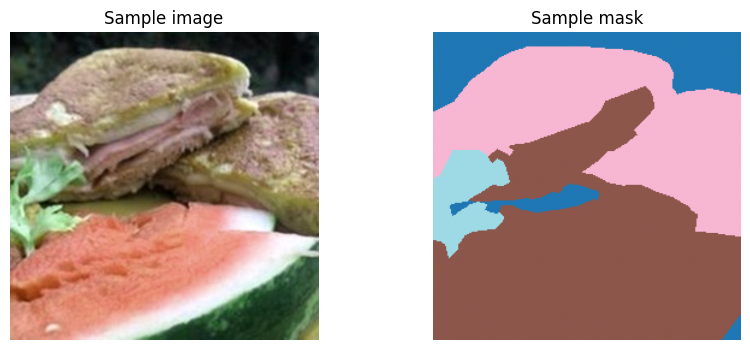

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/110M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b2-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150, 768, 1, 1]) vs model:torch.Size([104, 768, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150]) vs model:torch.Size([104])                      

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


model.safetensors:   0%|          | 0.00/110M [00:00<?, ?B/s]

Model ready.
Epoch 01/30 | Train Loss: 2.0192 | Val mIoU: 0.0968 | Best: 0.0968 | LR: 0.0000598 | Time: 158.2s
Epoch 02/30 | Train Loss: 1.2573 | Val mIoU: 0.1439 | Best: 0.1439 | LR: 0.0000593 | Time: 117.3s
Epoch 03/30 | Train Loss: 1.0030 | Val mIoU: 0.2071 | Best: 0.2071 | LR: 0.0000585 | Time: 116.5s
Epoch 04/30 | Train Loss: 0.8441 | Val mIoU: 0.2536 | Best: 0.2536 | LR: 0.0000574 | Time: 117.1s
Epoch 05/30 | Train Loss: 0.7139 | Val mIoU: 0.2881 | Best: 0.2881 | LR: 0.0000560 | Time: 117.1s
Epoch 06/30 | Train Loss: 0.6091 | Val mIoU: 0.3209 | Best: 0.3209 | LR: 0.0000543 | Time: 117.2s
Epoch 07/30 | Train Loss: 0.5249 | Val mIoU: 0.3242 | Best: 0.3242 | LR: 0.0000523 | Time: 117.3s
Epoch 08/30 | Train Loss: 0.4587 | Val mIoU: 0.3419 | Best: 0.3419 | LR: 0.0000501 | Time: 117.0s
Epoch 09/30 | Train Loss: 0.3972 | Val mIoU: 0.3496 | Best: 0.3496 | LR: 0.0000476 | Time: 116.9s
Epoch 10/30 | Train Loss: 0.3482 | Val mIoU: 0.3586 | Best: 0.3586 | LR: 0.0000450 | Time: 116.6s
Epoch 1

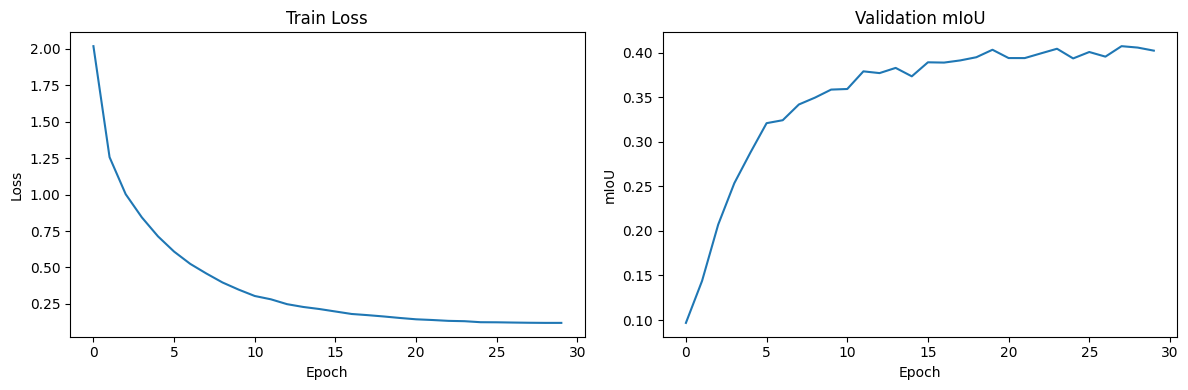

Saved curves to: /content/drive/MyDrive/AAI/Task1/segformer_b2_foodseg/segformer_b2_training_curves.png


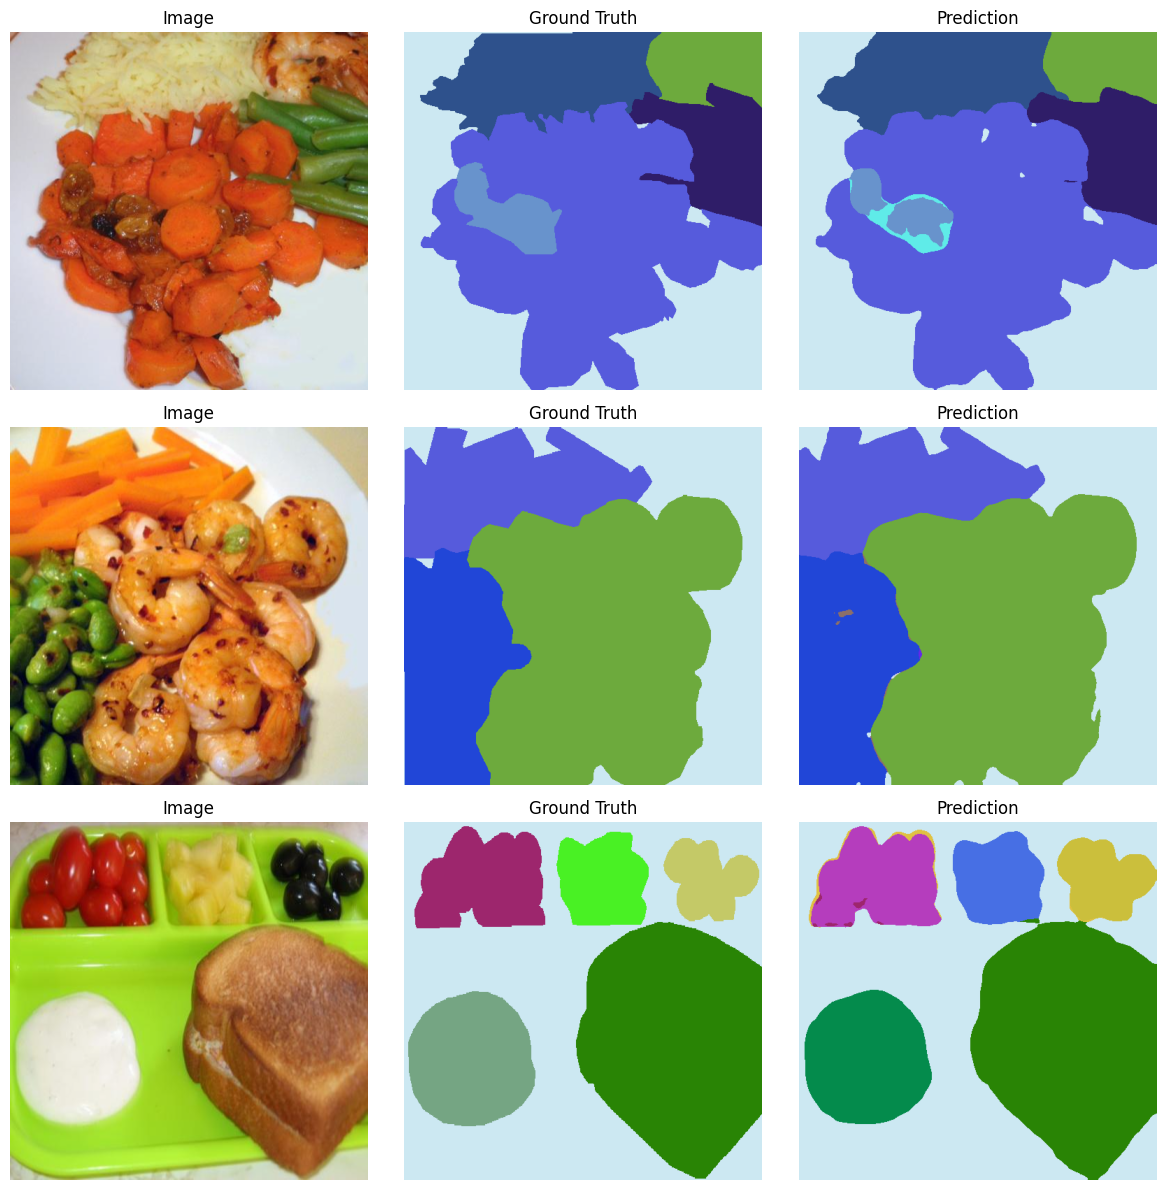

Saved prediction examples to: /content/drive/MyDrive/AAI/Task1/segformer_b2_foodseg/segformer_b2_predictions.png
Saved summary to: /content/drive/MyDrive/AAI/Task1/segformer_b2_foodseg/segformer_b2_foodseg_summary.txt


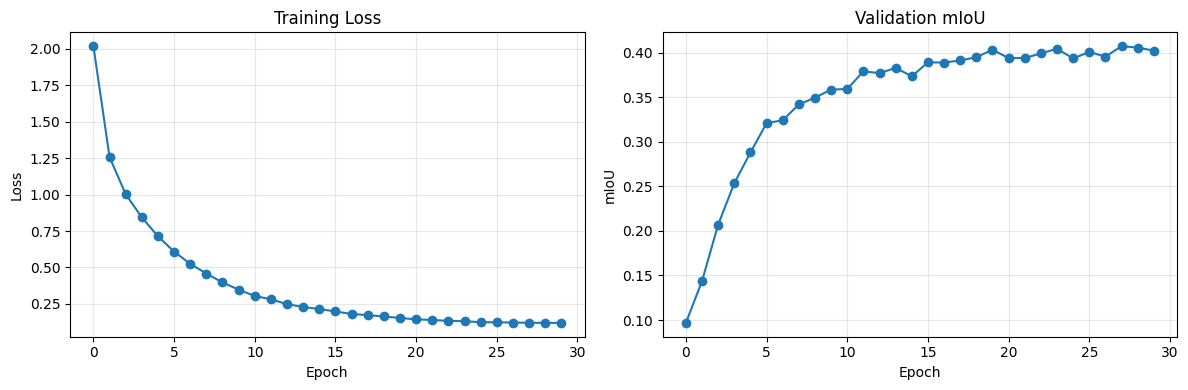

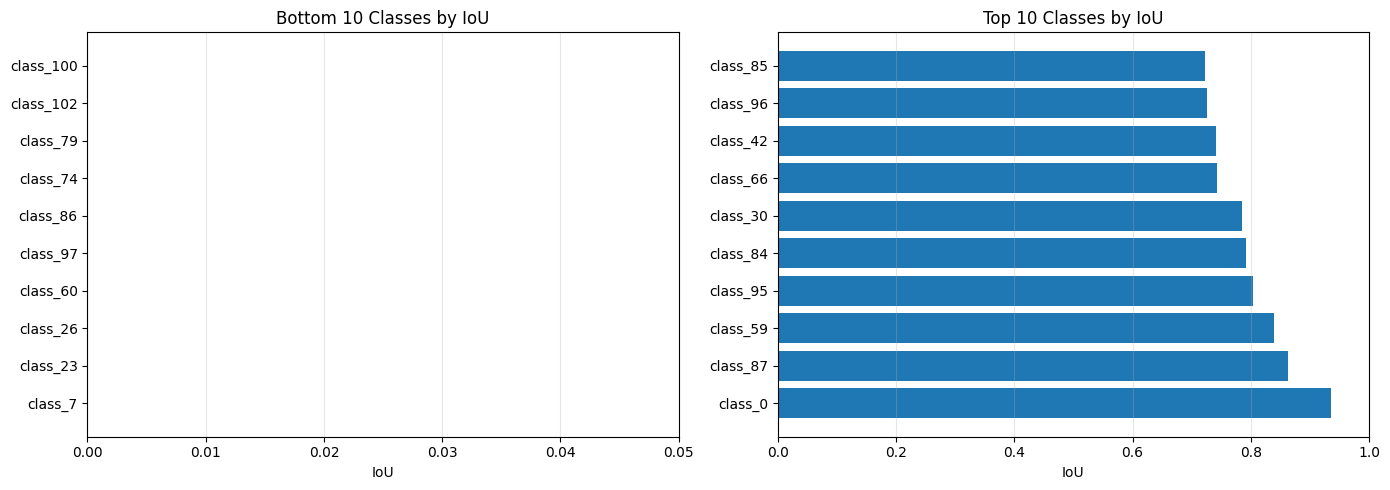

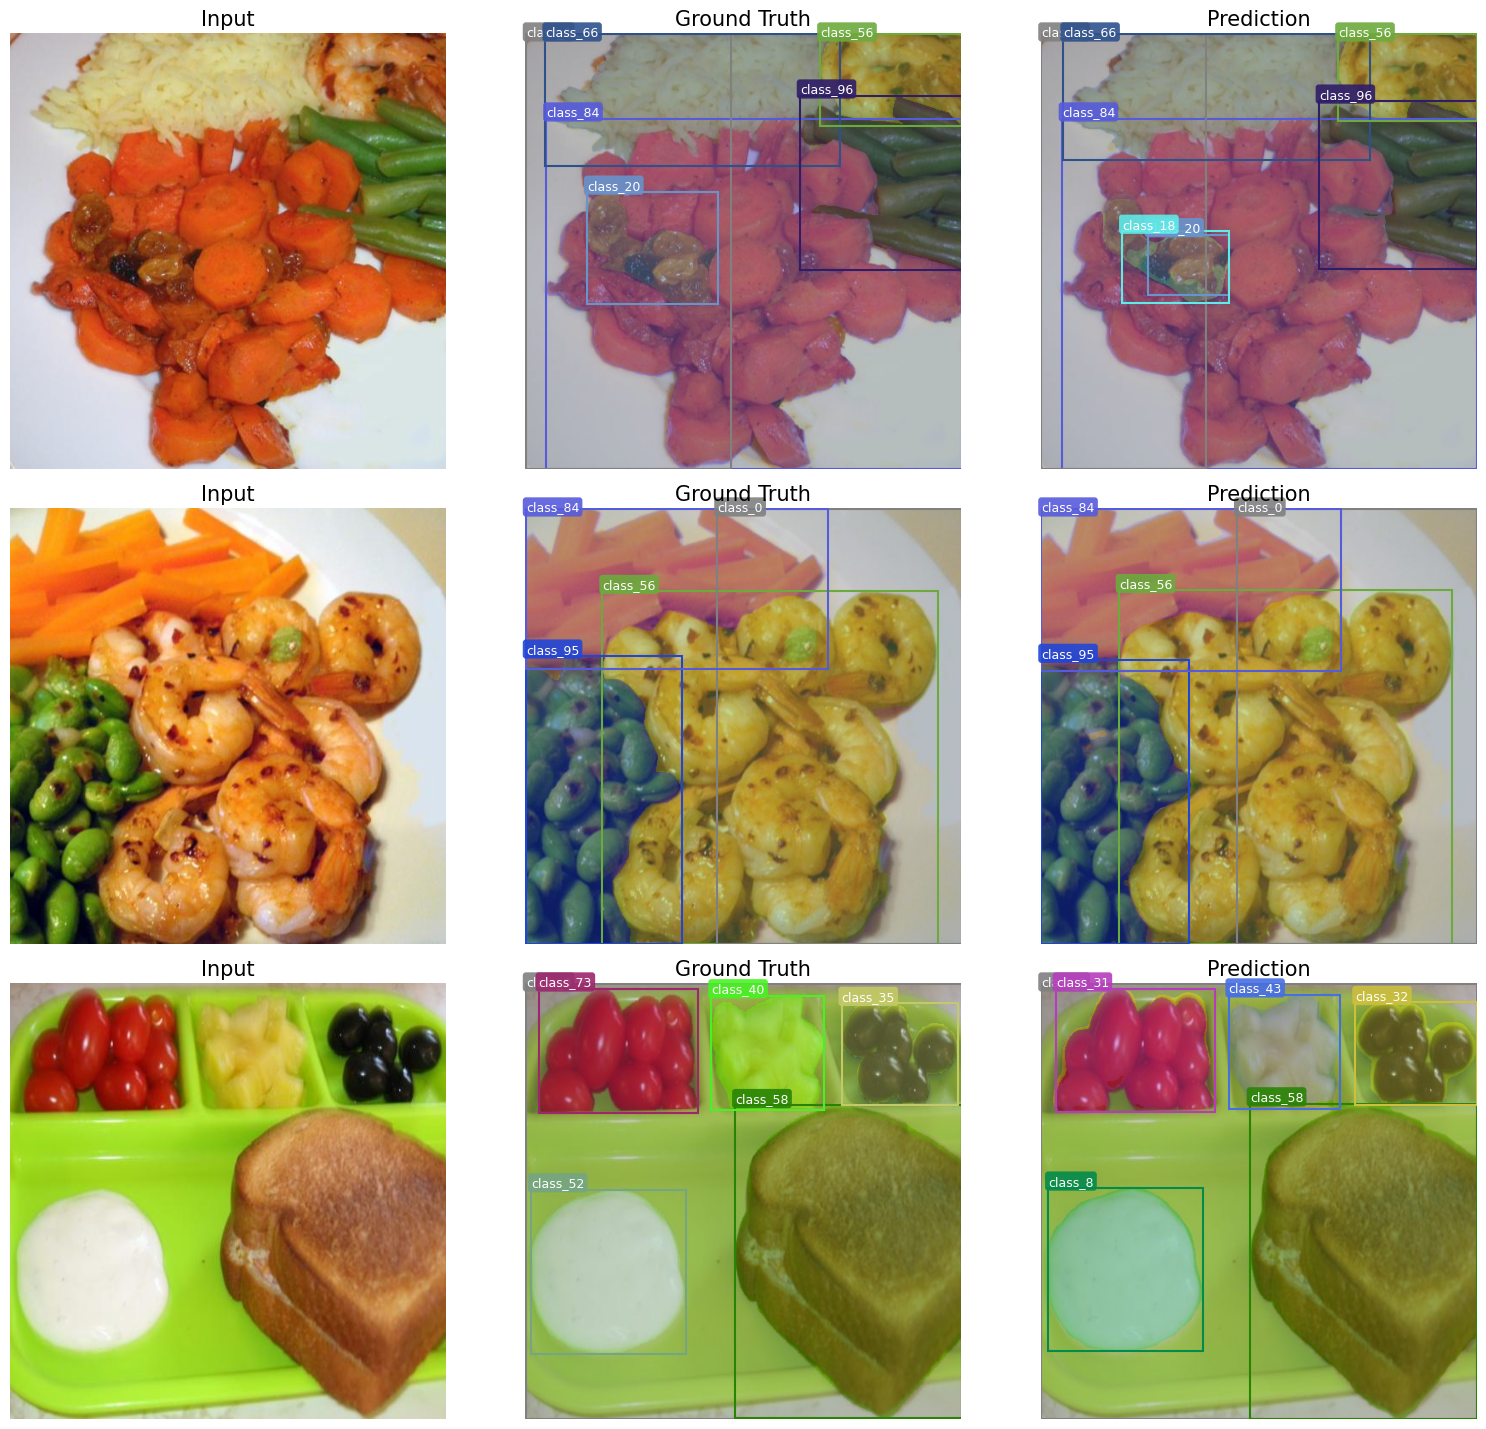

In [ ]:
!pip install -q transformers albumentations opencv-python matplotlib accelerate

from google.colab import drive
drive.mount('/content/drive')

import os
import cv2
import time
import shutil
import random
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from collections import defaultdict
import torch
import torch.nn as nn
import torch.nn.functional as F

import albumentations as A
from torch.utils.data import Dataset, DataLoader
from albumentations.pytorch import ToTensorV2

from transformers import SegformerForSemanticSegmentation

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True
except:
    pass

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Dataset path
DRIVE_DATASET_PATH = "/content/drive/MyDrive/AAI/Task1/FoodSeg103"
LOCAL_DATASET_PATH = "/content/FoodSeg103"

USE_LOCAL_COPY = True

if USE_LOCAL_COPY:
    if not os.path.exists(LOCAL_DATASET_PATH):
        print("Copying dataset from Google Drive to local Colab storage.")
        shutil.copytree(DRIVE_DATASET_PATH, LOCAL_DATASET_PATH)
        print("Copy complete.")
    else:
        print("Using existing local dataset copy.")
    DATASET_PATH = LOCAL_DATASET_PATH
else:
    print("Using dataset directly from Google Drive.")
    DATASET_PATH = DRIVE_DATASET_PATH

TRAIN_IMAGE_PATH = os.path.join(DATASET_PATH, "Images", "img_dir", "train")
TRAIN_MASK_PATH  = os.path.join(DATASET_PATH, "Images", "ann_dir", "train")
TEST_IMAGE_PATH  = os.path.join(DATASET_PATH, "Images", "img_dir", "test")
TEST_MASK_PATH   = os.path.join(DATASET_PATH, "Images", "ann_dir", "test")

assert os.path.exists(TRAIN_IMAGE_PATH), f"Missing: {TRAIN_IMAGE_PATH}"
assert os.path.exists(TRAIN_MASK_PATH),  f"Missing: {TRAIN_MASK_PATH}"
assert os.path.exists(TEST_IMAGE_PATH),  f"Missing: {TEST_IMAGE_PATH}"
assert os.path.exists(TEST_MASK_PATH),   f"Missing: {TEST_MASK_PATH}"

# File lists
train_images = sorted([x for x in os.listdir(TRAIN_IMAGE_PATH) if x.lower().endswith(".jpg")])
test_images  = sorted([x for x in os.listdir(TEST_IMAGE_PATH) if x.lower().endswith(".jpg")])

train_image_paths = [os.path.join(TRAIN_IMAGE_PATH, x) for x in train_images]
train_mask_paths  = [os.path.join(TRAIN_MASK_PATH, x.replace(".jpg", ".png")) for x in train_images]

test_image_paths  = [os.path.join(TEST_IMAGE_PATH, x) for x in test_images]
test_mask_paths   = [os.path.join(TEST_MASK_PATH, x.replace(".jpg", ".png")) for x in test_images]

print("Train images:", len(train_image_paths))
print("Test images :", len(test_image_paths))

# Hyperparameters
NUM_CLASSES = 104
IMG_SIZE = 512

BATCH_SIZE = 4
EPOCHS = 30
LR = 6e-5
WEIGHT_DECAY = 1e-2
VAL_RATIO = 0.1
NUM_WORKERS = 2
PATIENCE = 8
ACCUM_STEPS = 1

MODEL_NAME = "nvidia/segformer-b2-finetuned-ade-512-512"

SAVE_DIR = "/content/drive/MyDrive/AAI/Task1/segformer_b2_foodseg"
os.makedirs(SAVE_DIR, exist_ok=True)

best_model_path  = os.path.join(SAVE_DIR, "best_segformer_b2_foodseg_checkpoint.pth")
clean_weights_path = os.path.join(SAVE_DIR, "segformer_b2_foodseg_weights.pth")
summary_path     = os.path.join(SAVE_DIR, "segformer_b2_foodseg_summary.txt")
curves_path      = os.path.join(SAVE_DIR, "segformer_b2_training_curves.png")
examples_path    = os.path.join(SAVE_DIR, "segformer_b2_predictions.png")

# Transforms
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_LINEAR),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.08,
        p=0.4
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_LINEAR),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
    ToTensorV2()
])

# Dataset
class FoodDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]

        img = cv2.imread(img_path)
        if img is None:
            raise ValueError(f"Failed to read image: {img_path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise ValueError(f"Failed to read mask: {mask_path}")

        if self.transform is not None:
            aug = self.transform(image=img, mask=mask)
            img = aug["image"]
            mask = aug["mask"].long()
        else:
            img = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
            mask = torch.from_numpy(mask).long()

        return img, mask

# Train / val split
indices = list(range(len(train_image_paths)))
random.shuffle(indices)

split = int((1.0 - VAL_RATIO) * len(indices))
train_idx = indices[:split]
val_idx   = indices[split:]

train_dataset = FoodDataset(
    [train_image_paths[i] for i in train_idx],
    [train_mask_paths[i] for i in train_idx],
    transform=train_transform
)

val_dataset = FoodDataset(
    [train_image_paths[i] for i in val_idx],
    [train_mask_paths[i] for i in val_idx],
    transform=val_transform
)

test_dataset = FoodDataset(
    test_image_paths,
    test_mask_paths,
    transform=val_transform
)

print("Train split:", len(train_dataset))
print("Val split  :", len(val_dataset))
print("Test set   :", len(test_dataset))

# Dataloaders
loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0)
)
if NUM_WORKERS > 0:
    loader_kwargs["prefetch_factor"] = 2

train_loader = DataLoader(train_dataset, shuffle=True, drop_last=True, **loader_kwargs)
val_loader   = DataLoader(val_dataset, shuffle=False, drop_last=False, **loader_kwargs)
test_loader  = DataLoader(test_dataset, shuffle=False, drop_last=False, **loader_kwargs)

# Sanity checks
images, masks = next(iter(train_loader))
print("Batch image shape:", images.shape)
print("Batch mask shape :", masks.shape)
print("Mask min/max     :", masks.min().item(), masks.max().item())

assert masks.min().item() >= 0
assert masks.max().item() < NUM_CLASSES

def denorm_image(img_tensor):
    img = img_tensor.detach().cpu().permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img * std + mean
    img = np.clip(img, 0, 1)
    return img

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(denorm_image(images[0]))
plt.title("Sample image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(masks[0].cpu().numpy(), cmap="tab20")
plt.title("Sample mask")
plt.axis("off")
plt.show()

# Model
id2label = {i: f"class_{i}" for i in range(NUM_CLASSES)}
label2id = {v: k for k, v in id2label.items()}

model = SegformerForSemanticSegmentation.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
).to(device)

print("Model ready.")

# Loss
ce_loss = nn.CrossEntropyLoss()

def loss_fn(logits, targets):
    return ce_loss(logits, targets)

# Optimizer + scheduler + AMP
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

use_amp = torch.cuda.is_available()
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except:
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

# Metrics
def update_confusion_matrix(confmat, preds, targets, num_classes):
    preds = preds.view(-1)
    targets = targets.view(-1)

    valid = (targets >= 0) & (targets < num_classes)
    preds = preds[valid]
    targets = targets[valid]

    inds = num_classes * targets + preds
    confmat += torch.bincount(
        inds,
        minlength=num_classes * num_classes
    ).reshape(num_classes, num_classes)

    return confmat

def compute_per_class_iou(confmat):
    confmat = confmat.float()
    intersection = torch.diag(confmat)
    union = confmat.sum(dim=1) + confmat.sum(dim=0) - intersection
    valid = union > 0
    iou = torch.zeros_like(intersection)
    iou[valid] = intersection[valid] / (union[valid] + 1e-7)
    return iou, valid

def compute_miou_from_confmat(confmat):
    iou, valid = compute_per_class_iou(confmat)
    if valid.sum() == 0:
        return 0.0
    return iou[valid].mean().item()

def resize_logits_to_target(logits, target):
    return F.interpolate(
        logits,
        size=target.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

@torch.no_grad()
def predict_with_tta(model, images):
    logits = model(pixel_values=images).logits
    logits = resize_logits_to_target(logits, images)

    flipped_images = torch.flip(images, dims=[3])
    flipped_logits = model(pixel_values=flipped_images).logits
    flipped_logits = resize_logits_to_target(flipped_logits, images)
    flipped_logits = torch.flip(flipped_logits, dims=[3])

    return 0.5 * (logits + flipped_logits)

# Training loop
best_val_miou = 0.0
best_epoch = -1
epochs_without_improve = 0

train_losses = []
val_mious = []
lrs = []

for epoch in range(EPOCHS):
    start_time = time.time()

    # train
    model.train()
    running_loss = 0.0
    optimizer.zero_grad(set_to_none=True)

    for step, (images, masks) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(pixel_values=images).logits
            logits = resize_logits_to_target(logits, masks)
            loss = loss_fn(logits, masks) / ACCUM_STEPS

        scaler.scale(loss).backward()

        if (step + 1) % ACCUM_STEPS == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item() * ACCUM_STEPS
        lrs.append(optimizer.param_groups[0]["lr"])

    scheduler.step()

    avg_train_loss = running_loss / max(len(train_loader), 1)
    train_losses.append(avg_train_loss)

    # validation
    model.eval()
    confmat = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=device)

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            logits = model(pixel_values=images).logits
            logits = resize_logits_to_target(logits, masks)
            preds = torch.argmax(logits, dim=1)

            confmat = update_confusion_matrix(confmat, preds, masks, NUM_CLASSES)

    val_miou = compute_miou_from_confmat(confmat)
    val_mious.append(val_miou)

    if val_miou > best_val_miou:
        best_val_miou = val_miou
        best_epoch = epoch + 1
        epochs_without_improve = 0

        save_obj = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_miou": best_val_miou,
            "num_classes": NUM_CLASSES,
            "model_name": MODEL_NAME,
            "img_size": IMG_SIZE
        }
        torch.save(save_obj, best_model_path)
    else:
        epochs_without_improve += 1

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val mIoU: {val_miou:.4f} | "
        f"Best: {best_val_miou:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.7f} | "
        f"Time: {time.time() - start_time:.1f}s"
    )

    if epochs_without_improve >= PATIENCE:
        print(f"\nEarly stopping triggered after {epoch+1} epochs.")
        break

print("\nBest validation mIoU:", best_val_miou)
print("Best epoch          :", best_epoch)

# Load best model
checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
print("Loaded best model.")

# Final test evaluation
model.eval()
test_confmat = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=device)

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        logits = predict_with_tta(model, images)
        preds = torch.argmax(logits, dim=1)

        test_confmat = update_confusion_matrix(test_confmat, preds, masks, NUM_CLASSES)

final_test_miou = compute_miou_from_confmat(test_confmat)
print("\nFinal Test mIoU:", final_test_miou)

# Save weights
torch.save(model.state_dict(), clean_weights_path)
print("Saved clean weights to:", clean_weights_path)

# Training curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses)
plt.title("Train Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(val_mious)
plt.title("Validation mIoU")
plt.xlabel("Epoch")
plt.ylabel("mIoU")

plt.tight_layout()
plt.savefig(curves_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved curves to: {curves_path}")

# Prediction examples
def colorize_mask(mask):
    rng = np.random.default_rng(123)
    colors = rng.integers(0, 255, size=(NUM_CLASSES, 3), dtype=np.uint8)
    return colors[mask]

model.eval()
sample_count = min(3, len(test_dataset))

fig, axes = plt.subplots(sample_count, 3, figsize=(12, 4 * sample_count))
if sample_count == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for i in range(sample_count):
        img, gt_mask = test_dataset[i]
        inp = img.unsqueeze(0).to(device)

        logits = predict_with_tta(model, inp)
        pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

        img_np = denorm_image(img)
        gt_np = gt_mask.cpu().numpy()

        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(colorize_mask(gt_np))
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(colorize_mask(pred_mask))
        axes[i, 2].set_title("Prediction")
        axes[i, 2].axis("off")

plt.tight_layout()
plt.savefig(examples_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"Saved prediction examples to: {examples_path}")

# Save summary
with open(summary_path, "w") as f:
    f.write("SEGFORMER-B2 FOODSEG103 RESULTS\n")
    f.write("================================\n")
    f.write(f"Model: SegFormerForSemanticSegmentation\n")
    f.write(f"Pretrained model: {MODEL_NAME}\n")
    f.write(f"Input size: {IMG_SIZE}x{IMG_SIZE}\n")
    f.write(f"Batch size: {BATCH_SIZE}\n")
    f.write(f"Epochs requested: {EPOCHS}\n")
    f.write(f"Best epoch: {best_epoch}\n")
    f.write(f"Learning rate: {LR}\n")
    f.write(f"Weight decay: {WEIGHT_DECAY}\n")
    f.write(f"Validation ratio: {VAL_RATIO}\n")
    f.write(f"Best validation mIoU: {best_val_miou:.6f}\n")
    f.write(f"Final test mIoU: {final_test_miou:.6f}\n")

print(f"Saved summary to: {summary_path}")

# Plot

try:
    class_names
    assert len(class_names) == NUM_CLASSES
except:
    class_names = [f"class_{i}" for i in range(NUM_CLASSES)]

# Helper functions
def build_fixed_colormap(num_classes, seed=123):
    rng = np.random.default_rng(seed)
    colors = rng.integers(0, 255, size=(num_classes, 3), dtype=np.uint8)
    colors[0] = np.array([128, 128, 128], dtype=np.uint8)  # class 0 in gray
    return colors

COLORS = build_fixed_colormap(NUM_CLASSES)

def colorize_mask(mask, colors=COLORS):
    return colors[mask]

def overlay_mask_on_image(image_rgb, mask, alpha=0.45, colors=COLORS):
    if image_rgb.dtype != np.uint8:
        base = (np.clip(image_rgb, 0, 1) * 255).astype(np.uint8)
    else:
        base = image_rgb.copy()

    color_mask = colorize_mask(mask, colors)
    overlay = cv2.addWeighted(base, 1 - alpha, color_mask, alpha, 0)
    return overlay

def get_connected_components_for_labels(mask, min_area=400):
    results = []
    labels_present = np.unique(mask)

    for cls_id in labels_present:
        binary = (mask == cls_id).astype(np.uint8)
        if binary.sum() == 0:
            continue

        num_cc, cc_map, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)

        best_area = 0
        best_box = None

        # skip component 0
        for comp_id in range(1, num_cc):
            x, y, w, h, area = stats[comp_id]
            if area >= min_area and area > best_area:
                best_area = area
                best_box = (x, y, w, h, area)

        if best_box is not None:
            results.append((cls_id, best_box))

    return results

def draw_labels(ax, mask, colors=COLORS, class_names=None, min_area=400, max_labels=8):
    comps = get_connected_components_for_labels(mask, min_area=min_area)

    # Sort by component area descending
    comps = sorted(comps, key=lambda x: x[1][4], reverse=True)[:max_labels]

    for cls_id, (x, y, w, h, area) in comps:
        color = colors[cls_id] / 255.0
        rect = patches.Rectangle(
            (x, y), w, h,
            linewidth=1.5,
            edgecolor=color,
            facecolor='none'
        )
        ax.add_patch(rect)

        label = class_names[cls_id] if class_names is not None else str(cls_id)
        ax.text(
            x,
            max(y - 4, 2),
            label,
            fontsize=9,
            color="white",
            bbox=dict(
                facecolor=color,
                edgecolor='none',
                alpha=0.9,
                boxstyle='round,pad=0.25'
            )
        )

def compute_per_class_iou_from_confmat(confmat):
    confmat = confmat.float()
    intersection = torch.diag(confmat)
    union = confmat.sum(dim=1) + confmat.sum(dim=0) - intersection
    valid = union > 0
    iou = torch.zeros_like(intersection)
    iou[valid] = intersection[valid] / (union[valid] + 1e-7)
    return iou.cpu().numpy(), valid.cpu().numpy()

# Rebuild test_confmat if not present
if "test_confmat" not in globals():
    print("test_confmat not found. Recomputing on test set.")
    model.eval()
    test_confmat = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=device)

    @torch.no_grad()
    def update_confusion_matrix_local(confmat, preds, targets, num_classes):
        preds = preds.view(-1)
        targets = targets.view(-1)

        valid = (targets >= 0) & (targets < num_classes)
        preds = preds[valid]
        targets = targets[valid]

        inds = num_classes * targets + preds
        confmat += torch.bincount(
            inds,
            minlength=num_classes * num_classes
        ).reshape(num_classes, num_classes)

        return confmat

    with torch.no_grad():
        for img, mask in test_loader:
            img = img.to(device)
            mask = mask.to(device)

            logits = predict_with_tta(model, img)
            preds = torch.argmax(logits, dim=1)

            test_confmat = update_confusion_matrix_local(test_confmat, preds, mask, NUM_CLASSES)

# Plot training curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, marker='o')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(val_mious, marker='o')
plt.title("Validation mIoU")
plt.xlabel("Epoch")
plt.ylabel("mIoU")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot IoU bars
ious, valid_mask = compute_per_class_iou_from_confmat(test_confmat)
valid_indices = np.where(valid_mask)[0]
valid_ious = ious[valid_indices]

sorted_idx = valid_indices[np.argsort(valid_ious)]

k = min(10, len(sorted_idx))
bottom_k = sorted_idx[:k]
top_k = sorted_idx[-k:][::-1]

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.barh(
    [class_names[i] for i in bottom_k],
    [ious[i] for i in bottom_k]
)
plt.title(f"Bottom {k} Classes by IoU")
plt.xlabel("IoU")
plt.xlim(0, max(0.05, np.max([ious[i] for i in bottom_k]) * 1.15))
plt.grid(True, axis='x', alpha=0.3)

plt.subplot(1, 2, 2)
plt.barh(
    [class_names[i] for i in top_k],
    [ious[i] for i in top_k]
)
plt.title(f"Top {k} Classes by IoU")
plt.xlabel("IoU")
plt.xlim(0, 1.0)
plt.grid(True, axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# Visualize Segmented Examples
def show_segmented_examples(
    model,
    dataset,
    device,
    class_names,
    num_examples=3,
    start_idx=0,
    use_tta=True,
    overlay_alpha=0.45,
    min_area=400,
    max_labels=8,
    figsize=(16, 5)
):
    model.eval()

    rows = num_examples
    fig, axes = plt.subplots(rows, 3, figsize=(figsize[0], figsize[1] * rows))

    if rows == 1:
        axes = np.expand_dims(axes, axis=0)

    with torch.no_grad():
        for r in range(rows):
            idx = start_idx + r
            if idx >= len(dataset):
                break

            img_tensor, gt_mask_tensor = dataset[idx]
            inp = img_tensor.unsqueeze(0).to(device)

            if use_tta:
                logits = predict_with_tta(model, inp)
            else:
                logits = model(inp)

            pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()
            gt_mask = gt_mask_tensor.cpu().numpy()
            img_rgb = denorm_image(img_tensor)

            gt_overlay = overlay_mask_on_image(img_rgb, gt_mask, alpha=overlay_alpha)
            pred_overlay = overlay_mask_on_image(img_rgb, pred_mask, alpha=overlay_alpha)

            # Column 1: input
            axes[r, 0].imshow(img_rgb)
            axes[r, 0].set_title("Input", fontsize=15)
            axes[r, 0].axis("off")

            # Column 2: GT
            axes[r, 1].imshow(gt_overlay)
            axes[r, 1].set_title("Ground Truth", fontsize=15)
            draw_labels(
                axes[r, 1],
                gt_mask,
                colors=COLORS,
                class_names=class_names,
                min_area=min_area,
                max_labels=max_labels
            )
            axes[r, 1].axis("off")

            # Column 3: Prediction
            axes[r, 2].imshow(pred_overlay)
            axes[r, 2].set_title("Prediction", fontsize=15)
            draw_labels(
                axes[r, 2],
                pred_mask,
                colors=COLORS,
                class_names=class_names,
                min_area=min_area,
                max_labels=max_labels
            )
            axes[r, 2].axis("off")

    plt.tight_layout()
    plt.show()

# Example Visualization
show_segmented_examples(
    model=model,
    dataset=test_dataset,
    device=device,
    class_names=class_names,
    num_examples=3,
    start_idx=0,
    use_tta=True,
    overlay_alpha=0.40,
    min_area=500,
    max_labels=8,
    figsize=(16, 4.8)
)

In [ ]:
# Loading Best Model
checkpoint = torch.load(best_model_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])

# Local Saving
clean_weights_path = "/content/foodseg_model_weights.pth"
torch.save(model.state_dict(), clean_weights_path)

print("Saved clean weights to:", clean_weights_path)

from google.colab import files
files.download(clean_weights_path)

# Copy to Drive
import shutil
drive_path = "/content/drive/MyDrive/foodseg_segformer_b2_weights.pth"
shutil.copy(clean_weights_path, drive_path)

print("Copied to Drive:", drive_path)

## **Demo**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import torch
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
from transformers import SegformerForSemanticSegmentation

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_CLASSES = 104
IMG_SIZE = 512

# rebuild model
model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b2-finetuned-ade-512-512",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
)

# loading saved weights
weights_path = "/content/drive/MyDrive/foodseg_segformer_b2_weights.pth"
model.load_state_dict(torch.load(weights_path, map_location=device))

model = model.to(device)
model.eval()

print("Model loaded successfully!")

from google.colab import files
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

Mounted at /content/drive


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/110M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b2-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150]) vs model:torch.Size([104])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([150, 768, 1, 1]) vs model:torch.Size([104, 768, 1, 1])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


model.safetensors:   0%|          | 0.00/110M [00:00<?, ?B/s]

Model loaded successfully!


Saving 00004402.jpg to 00004402.jpg


In [2]:
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

orig_h, orig_w = image.shape[:2]

image_resized = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
image_resized = image_resized / 255.0

# normalize
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
image_resized = (image_resized - mean) / std

# to tensor
image_tensor = torch.tensor(image_resized).permute(2, 0, 1).float().unsqueeze(0).to(device)

In [3]:
with torch.no_grad():
    outputs = model(pixel_values=image_tensor).logits

    # resize back to original size
    outputs = torch.nn.functional.interpolate(
        outputs,
        size=(orig_h, orig_w),
        mode="bilinear",
        align_corners=False
    )

    pred = torch.argmax(outputs, dim=1).squeeze().cpu().numpy()

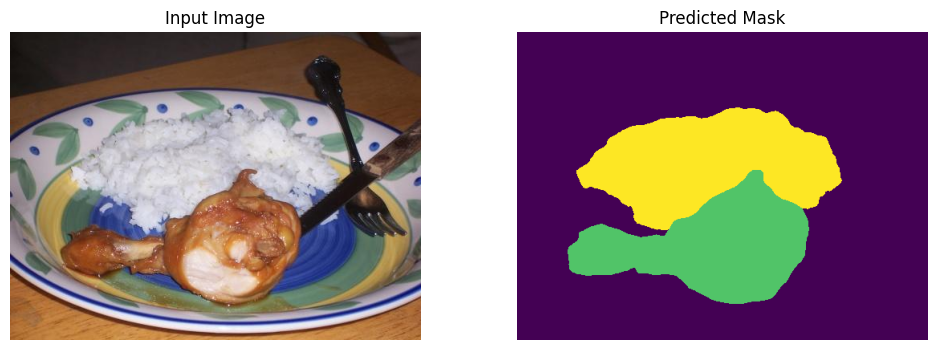

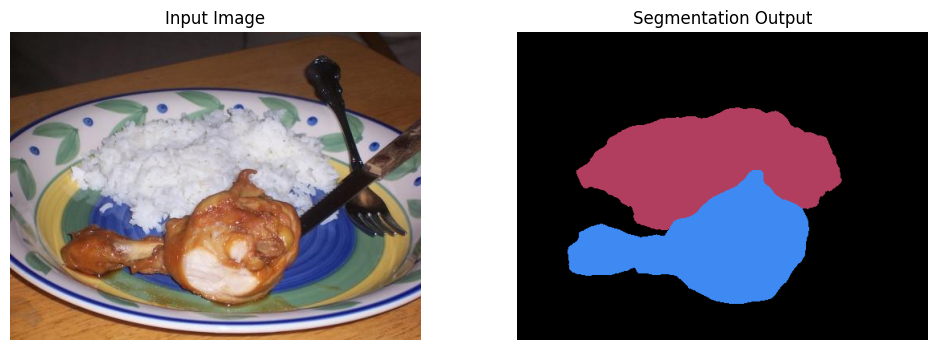

GT mask found: /content/drive/MyDrive/AAI/Task1/FoodSeg103/Images/ann_dir/test/00004402.png
GT mask shape: (384, 512)
Prediction shape: (384, 512)
   COMPARISON METRICS
Pixel Accuracy : 0.9857
Mean IoU       : 0.9577
Mean Dice      : 0.9783


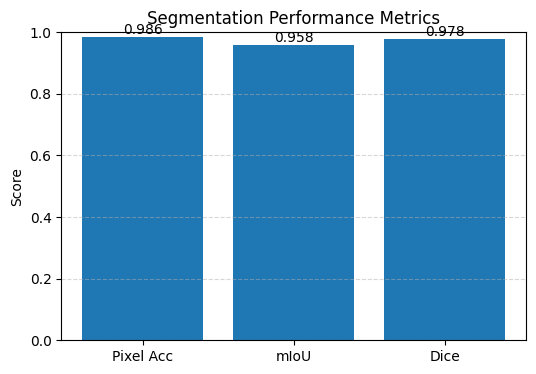

In [4]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(pred)
plt.title("Predicted Mask")
plt.axis("off")

plt.show()

def create_color_map(num_classes=104):
    np.random.seed(42)
    colors = np.random.randint(0, 255, (num_classes, 3))
    colors[0] = [0, 0, 0]
    return colors

color_map = create_color_map(NUM_CLASSES)

def mask_to_color(mask, color_map):
    h, w = mask.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)
    for cls in range(len(color_map)):
        color_mask[mask == cls] = color_map[cls]
    return color_mask

colored_pred = mask_to_color(pred, color_map)

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(colored_pred)
plt.title("Segmentation Output")
plt.axis("off")

plt.show()



# 1) GT Mask
image_name = os.path.basename(image_path)
mask_name = image_name.replace(".jpg", ".png").replace(".jpeg", ".png")

candidate_mask_paths = [
    f"/content/FoodSeg103/Images/ann_dir/test/{mask_name}",
    f"/content/FoodSeg103/Images/ann_dir/train/{mask_name}",
    f"/content/drive/MyDrive/AAI/Task1/FoodSeg103/Images/ann_dir/test/{mask_name}",
    f"/content/drive/MyDrive/AAI/Task1/FoodSeg103/Images/ann_dir/train/{mask_name}",
]

gt_mask = None
found_mask_path = None

for p in candidate_mask_paths:
    if os.path.exists(p):
        gt_mask = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        found_mask_path = p
        break

if gt_mask is None:
    print("No GT mask found for this image.")
    print("Comparison metrics cannot be computed unless the image is from the dataset.")
else:
    print("GT mask found:", found_mask_path)
    print("GT mask shape:", gt_mask.shape)
    print("Prediction shape:", pred.shape)

    # 2 Compute metrics
    pred_flat = pred.reshape(-1)
    gt_flat = gt_mask.reshape(-1)

    valid = (gt_flat >= 0) & (gt_flat < NUM_CLASSES)
    pred_flat = pred_flat[valid]
    gt_flat = gt_flat[valid]

    confmat = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for g, p in zip(gt_flat, pred_flat):
        confmat[g, p] += 1

    tp = np.diag(confmat)
    gt_sum = confmat.sum(axis=1)
    pred_sum = confmat.sum(axis=0)

    pixel_acc = tp.sum() / (confmat.sum() + 1e-7)

    union = gt_sum + pred_sum - tp
    iou = tp / (union + 1e-7)

    dice = 2 * tp / (gt_sum + pred_sum + 1e-7)

    valid_cls = union > 0
    miou = iou[valid_cls].mean() if valid_cls.any() else 0.0
    mean_dice = dice[valid_cls].mean() if valid_cls.any() else 0.0

    # 3 Print
    print("   COMPARISON METRICS")
    print(f"Pixel Accuracy : {pixel_acc:.4f}")
    print(f"Mean IoU       : {miou:.4f}")
    print(f"Mean Dice      : {mean_dice:.4f}")

    # Metrics Plot
    import matplotlib.pyplot as plt

    metrics_names = ["Pixel Acc", "mIoU", "Dice"]
    metrics_values = [pixel_acc, miou, mean_dice]

    plt.figure(figsize=(6,4))
    bars = plt.bar(metrics_names, metrics_values)

    # add values on top
    for i, v in enumerate(metrics_values):
        plt.text(i, v + 0.01, f"{v:.3f}", ha='center')

    plt.ylim(0, 1)
    plt.title("Segmentation Performance Metrics")
    plt.ylabel("Score")
    plt.grid(axis='y', linestyle='--', alpha=0.5)

    plt.show()
